# Прогнозирование дождя в Австралии

**Rain in Australia · Анализ данных и бинарная классификация**

Цель исследования — предсказать `RainTomorrow` по погодным наблюдениям и сравнить модели, способы обработки пропусков и варианты набора признаков.






## 1. EDA 




### 1.1. Загрузка и структура данных

In [ ]:
# Библиотеки и просмотр файлов, подключённых к Kaggle Notebook
import numpy as np
import pandas as pd
from IPython.display import display

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/jsphyg/weather-dataset-rattle-package/weatherAUS.csv


In [ ]:
# Исходный CSV. Вне Kaggle замените путь на расположение weatherAUS.csv.
file_path = "/kaggle/input/datasets/jsphyg/weather-dataset-rattle-package/weatherAUS.csv"

df = pd.read_csv(file_path)

print("First 5 records:", df.head())
print(df.columns)

First 5 records:          Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  Temp3pm  RainToday  \
0

In [ ]:
# Размер датасета
df.shape

(145460, 23)

In [ ]:
# Типы данных и количество непустых значений
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

**Наблюдение.** В исходной таблице 145 460 строк и 23 столбца. Есть 16 числовых столбцов и 7 столбцов типа `object`, включая дату и целевую переменную. `RainTomorrow` принимает значения `Yes` / `No`; часть ответов отсутствует.

<a id="eda-target"></a>

### 1.2. Распределение целевой переменной

In [ ]:
# Распределение целевой переменной
df["RainTomorrow"].value_counts(normalize=True, dropna=False)

RainTomorrow
No     0.758394
Yes    0.219146
NaN    0.022460
Name: proportion, dtype: float64

**Наблюдение.** Среди всех строк доля `No` составляет около 75.84%, `Yes` — 21.91%, а неизвестных ответов — 2.25%. После исключения неизвестной цели доля класса `No` составляет примерно 77.6%. Поэтому одной Accuracy недостаточно: далее дополнительно используются Precision, Recall, F1 и ROC-AUC.

<a id="eda-missing"></a>

### 1.3. Доли пропущенных значений

Доля пропусков вычисляется отдельно для каждого столбца:

$$
p_j=\frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\{x_{ij}\text{ отсутствует}\}\cdot100\%.
$$

В коде среднее булевых значений `df.isna()` соответствует доле пропусков.

In [ ]:
missing = df.isna().mean() * 100

missing.sort_values(ascending=False)

Sunshine         48.009762
Evaporation      43.166506
Cloud3pm         40.807095
Cloud9am         38.421559
Pressure9am      10.356799
Pressure3pm      10.331363
WindDir9am        7.263853
WindGustDir       7.098859
WindGustSpeed     7.055548
Humidity3pm       3.098446
WindDir3pm        2.906641
Temp3pm           2.481094
RainTomorrow      2.245978
Rainfall          2.241853
RainToday         2.241853
WindSpeed3pm      2.105046
Humidity9am       1.824557
WindSpeed9am      1.214767
Temp9am           1.214767
MinTemp           1.020899
MaxTemp           0.866905
Date              0.000000
Location          0.000000
dtype: float64

**Наблюдение.** Наибольшая доля пропусков у `Sunshine` (48.01%), `Evaporation` (43.17%), `Cloud3pm` (40.81%) и `Cloud9am` (38.42%). На этом этапе признаки не удаляются и значения не заполняются: способы обработки проверяются позже внутри моделей.

<a id="eda-location"></a>

### 1.4. Связь пропусков с местоположением

Сравним доли отсутствующих значений `Sunshine` и `Evaporation` по `Location`.

In [ ]:
df.groupby("Location")["Sunshine"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

Location
Albury              100.000000
GoldCoast           100.000000
BadgerysCreek       100.000000
Bendigo             100.000000
Ballarat            100.000000
Katherine           100.000000
Wollongong          100.000000
Walpole             100.000000
Uluru               100.000000
Richmond            100.000000
SalmonGums          100.000000
Penrith             100.000000
NorahHead           100.000000
Nhil                100.000000
MountGinini         100.000000
Newcastle           100.000000
Launceston          100.000000
Tuggeranong         100.000000
Witchcliffe         100.000000
Cobar                81.721502
Canberra             55.733411
Williamtown          54.968428
CoffsHarbour         50.348953
Adelaide             44.597557
Sale                 39.581256
Woomera              33.300100
Moree                31.704885
AliceSprings         17.105263
Albany               17.105263
Cairns               15.657895
Portland             14.722499
Dartmoor             14.722499

In [ ]:
df.groupby("Location")["Evaporation"].apply(
    lambda x: x.isna().mean() * 100
).sort_values(ascending=False)

Location
Albury              100.000000
Ballarat            100.000000
BadgerysCreek       100.000000
GoldCoast           100.000000
PearceRAAF          100.000000
Witchcliffe         100.000000
Wollongong          100.000000
Walpole             100.000000
Uluru               100.000000
SalmonGums          100.000000
Tuggeranong         100.000000
Penrith             100.000000
MountGinini         100.000000
Nhil                100.000000
NorahHead           100.000000
Newcastle           100.000000
Launceston           95.361842
Bendigo              61.019737
Canberra             46.682189
Adelaide             46.633260
Richmond             46.028581
CoffsHarbour         40.677966
Sale                 39.049518
Williamtown          35.327351
Moree                23.828514
Woomera              14.589565
Dartmoor             13.592556
Portland             13.592556
MountGambier         13.486842
Cairns               12.171053
Cobar                11.399136
Albany                9.539474

Для `Albury` все значения `Sunshine` отсутствуют. Следующая проверка показывает ограничение заполнения средним по городу: при отсутствии наблюдений среднее не определено.

In [ ]:
df.loc[df["Location"] == "Albury", "Sunshine"].mean()

nan

**Наблюдение.** Пропуски распределены по местоположениям неравномерно; для ряда городов доля достигает 100%. Это указывает на связь пропущенности с `Location`, но само по себе не устанавливает причину отсутствия измерений.

<a id="eda-statistics"></a>

### 1.5. Описательные статистики и крайние значения

In [ ]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.000000,144199.000000,142199.000000,82670.000000,75625.000000,135197.000000,143693.000000,142398.000000,142806.000000,140953.000000,130395.00000,130432.000000,89572.000000,86102.000000,143693.000000,141851.00000
mean,12.194034,23.221348,2.360918,5.468232,7.611178,40.035230,14.043426,18.662657,68.880831,51.539116,1017.64994,1015.255889,4.447461,4.509930,16.990631,21.68339
std,6.398495,7.119049,8.478060,4.193704,3.785483,13.607062,8.915375,8.809800,19.029164,20.795902,7.10653,7.037414,2.887159,2.720357,6.488753,6.93665
min,-8.500000,-4.800000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.50000,977.100000,0.000000,0.000000,-7.200000,-5.40000
25%,7.600000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.90000,1010.400000,1.000000,2.000000,12.300000,16.60000
50%,12.000000,22.600000,0.000000,4.800000,8.400000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.60000,1015.200000,5.000000,5.000000,16.700000,21.10000
75%,16.900000,28.200000,0.800000,7.400000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.40000,1020.000000,7.000000,7.000000,21.600000,26.40000
max,33.900000,48.100000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.00000,1039.600000,9.000000,9.000000,40.200000,46.70000


In [ ]:
df[["Rainfall", "Evaporation", "WindSpeed9am", "WindGustSpeed"]].quantile(
    [0.50, 0.75, 0.95, 0.99, 1.00]
)

,Rainfall,Evaporation,WindSpeed9am,WindGustSpeed
0.50,0.0,4.8,13.0,39.0
0.75,0.8,7.4,19.0,48.0
0.95,13.0,12.0,30.0,65.0
0.99,37.4,18.4,39.0,81.0
1.00,371.0,145.0,130.0,135.0


**Наблюдение.** У `Rainfall` медиана равна 0, среднее — около 2.36, а максимум — 371. У `Evaporation` 99-й процентиль равен 18.4 при максимуме 145. Эти значения требуют внимания, но в данном исследовании экстремальные наблюдения автоматически не удаляются.

<a id="eda-sunshine"></a>

### 1.6. Sunshine: пропуски и измеренные значения

Сначала сравниваются доли дождливых следующих дней при наличии и отсутствии измерения, затем — сами значения `Sunshine` в двух классах.

In [ ]:
pd.crosstab(
    df["Sunshine"].isna(),
    df["RainTomorrow"],
    normalize="index"
)

RainTomorrow,No,Yes
Sunshine,,
False,0.773841,0.226159
True,0.777987,0.222013


In [ ]:
df.groupby("RainTomorrow")["Sunshine"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
RainTomorrow,,,,
No,57556,8.546358,9.4,3.380298
Yes,16821,4.471761,4.3,3.359329


**Наблюдение.** Сам факт пропуска слабо связан с целью в объединённой выборке: доли `Yes` равны 22.62% и 22.20%. При этом измеренное `Sunshine` различается между классами: среднее составляет 8.55 часа перед днями без дождя и 4.47 часа перед дождливыми днями. Отсутствие сильной отдельной связи индикатора с целью ещё не доказывает его бесполезность в модели.

**Проверка по интервалам.** Оценим долю `RainTomorrow=Yes` для разных интервалов солнечных часов. Используются только строки с известными `Sunshine` и `RainTomorrow`.

In [ ]:
df_sun = df.dropna(subset=["Sunshine", "RainTomorrow"]).copy()

df_sun["Sunshine_bin"] = pd.cut(
    df_sun["Sunshine"],
    bins=[0, 3, 6, 9, 12, 15],
    include_lowest=True
)

df_sun.groupby("Sunshine_bin", observed=True)["RainTomorrow"].agg(
    count="count",
    rain_probability=lambda x: (x == "Yes").mean()
)

,count,rain_probability
Sunshine_bin,,
"(-0.001, 3.0]",12094,0.546552
"(3.0, 6.0]",11669,0.389494
"(6.0, 9.0]",17508,0.220756
"(9.0, 12.0]",25610,0.064389
"(12.0, 15.0]",7496,0.020277


**Проверка внутри одного города.** Повторим анализ для `Melbourne`, чтобы проверить, сохраняется ли наблюдаемая связь после фиксации местоположения.

In [ ]:
df_sun = df[df["Location"] == "Melbourne"].dropna(subset=["Sunshine", "RainTomorrow"]).copy()

# 2. Разбиваем количество солнечных часов на интервалы (бины)
df_sun["Sunshine_bin"] = pd.cut(
    df_sun["Sunshine"],
    bins=[0, 3, 6, 9, 12, 15],
    include_lowest=True
)

# 3. Группируем по интервалам и считаем вероятность дождя
df_sun.groupby("Sunshine_bin", observed=True)["RainTomorrow"].agg(
    count="count",
    rain_probability=lambda x: (x == "Yes").mean()
)

,count,rain_probability
Sunshine_bin,,
"(-0.001, 3.0]",594,0.481481
"(3.0, 6.0]",497,0.329980
"(6.0, 9.0]",615,0.204878
"(9.0, 12.0]",534,0.093633
"(12.0, 15.0]",194,0.051546


**Вывод EDA.** В объединённых данных доля дождливых следующих дней убывает с 54.66% при 0–3 солнечных часах до 2.03% при 12–15 часах. Для `Melbourne` наблюдается похожая картина: 48.15% и 5.15%. Это предсказательная связь в исследованных наблюдениях, а не доказательство причинного влияния. Анализ ограничен строками с известным `Sunshine`.

<a id="eda-evaporation"></a>

### 1.7. Evaporation и целевая переменная

In [ ]:
df.groupby("RainTomorrow")["Evaporation"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
RainTomorrow,,,,
No,63491,5.734807,5.0,4.332891
Yes,17859,4.527779,3.8,3.469052


In [ ]:
df_sun = df.dropna(subset=["Evaporation", "RainTomorrow"]).copy()

df_sun["Evaporation_bin"] = pd.cut(
    df_sun["Evaporation"],
    bins=[0, 3, 6, 9, 12, 15],
    include_lowest=True
)

df_sun.groupby("Evaporation_bin", observed=True)["RainTomorrow"].agg(
    count="count",
    rain_probability=lambda x: (x == "Yes").mean())

,count,rain_probability
Evaporation_bin,,
"(-0.001, 3.0]",24888,0.290381
"(3.0, 6.0]",27123,0.222284
"(6.0, 9.0]",18132,0.174553
"(9.0, 12.0]",7199,0.131546
"(12.0, 15.0]",2287,0.128115


**Наблюдение.** Среднее `Evaporation` составляет 5.73 для класса `No` и 4.53 для `Yes`. В приведённых интервалах доля дождливых следующих дней также уменьшается.

**Граница анализа:** в исходном коде интервалы `Evaporation` ограничены диапазоном 0–15. Значения выше 15 не попадают в эту интервальную таблицу, хотя присутствуют в описательных статистиках. Границы сохранены без изменения.



## гипотезы

В исходном ноутбуке есть первоначальные предположения и идеи, появившиеся по ходу EDA и обучения.


<a id="hypotheses-initial"></a>

### 2.1. Первоначальные направления исследования

В начале работы были записаны следующие идеи

| Первоначальная идея | Что сделано в ноутбуке |
|:--|:--|
| `Humidity3pm` информативнее `Humidity9am` | Сравнены индивидуальные F-score при отборе признаков; отдельного сравнения моделей с исключением каждого признака нет. |
| Местоположение и сезон повышают ROC-AUC | `Location` включён в модели; отдельно проверено добавление сезонности. Эксперимента без `Location` нет. |
| Random Forest превосходит логистическую регрессию | Сравнены исходные модели и конфигурации после настройки. |
| Accuracy недостаточно отражает качество при дисбалансе | Проверены DummyClassifier, метрики положительного класса и разные пороги. |
| Удаление признаков с долей пропусков более 40% не ухудшит качество | Совместное удаление всех таких столбцов не проверялось. |
| Исключение `Sunshine` и `Evaporation` не ухудшит ROC-AUC | Проведён более узкий эксперимент: исключён `Sunshine` вместе с его индикатором; совместного исключения двух признаков нет. |

<a id="hypotheses-register"></a>

### 2.2. Итоговый реестр проверяемых гипотез

| Код | Гипотеза | Способ проверки |
|:--|:--|:--|
| **H1** | `Sunshine` даёт дополнительную информацию для прогноза. | [Сравнение с признаком и без него](#exp-sunshine); удаляется также его индикатор пропуска. |
| **H2** | Индикаторы пропусков улучшают ROC-AUC. | [Одинаковая логистическая регрессия с индикаторами и без](#exp-indicators). |
| **H3** | Избыточная сложность дерева приводит к переобучению. | [Изменение глубины и минимального размера листа](#exp-depth). |
| **H4** | Настройка L2-регуляризации позволяет улучшить качество логистической регрессии. | [GridSearchCV по параметру C](#exp-regularization). |
| **H5** | Настройка гиперпараметров Random Forest улучшает ROC-AUC. | [RandomizedSearchCV](#exp-forest-search). |
| **H6** | Отбор 20 признаков по ANOVA F-statistic не ухудшит качество. | [Все признаки против SelectKBest(k=20)](#exp-selection). |
| **H7** | Информация о месяце повышает качество прогноза. | [Добавление month_sin и month_cos](#exp-season). |

Основная метрика сравнения — **ROC-AUC**. Отдельные ранние эксперименты с деревом проводятся на одной валидационной выборке; последующие сравнения — на одинаковых трёх временных фолдах. Выводы об улучшении относятся к проведённым экспериментам; статистическая значимость отдельно не проверялась.

<a id="preprocessing"></a>

## 3. Предобработка и схема оценки

Подготовка включает исключение строк с неизвестной целью, разделение по датам, выбор входных столбцов и создание общего препроцессора. Заполнение пропусков, масштабирование и кодирование обучаются внутри Pipeline, а не заранее на всей таблице.

<a id="prep-split"></a>

### 3.1. Отложенный тестовый период

In [ ]:
data = df.dropna(subset=["RainTomorrow"]).copy()
data["Date"] = pd.to_datetime(data["Date"])

dates = np.sort(data["Date"].unique())
split_date = dates[int(len(dates) * 0.8)]

train_df = data[data["Date"] < split_date].copy()
test_df = data[data["Date"] >= split_date].copy()

print("Дата разделения:", split_date)
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Дата разделения: 2015-08-08T00:00:00.000000000
Train: (109302, 23)
Test: (32891, 23)


**Результат.** Граница теста — **8 августа 2015 года**. До неё остаются 109 302 строки (`train_df`), начиная с неё — 32 891 строка (`test_df`). Разделение выполнено по 80% уникальных дат, поэтому доли строк отличаются от 80/20. Тест не используется для выбора моделей и гиперпараметров.

<a id="prep-validation"></a>

### 3.2. Отдельная валидация для первых экспериментов

In [ ]:
train_dates = np.sort(train_df["Date"].unique())
val_date = train_dates[int(len(train_dates) * 0.8)]

fit_df = train_df[train_df["Date"] < val_date].copy()
val_df = train_df[train_df["Date"] >= val_date].copy()

print("Train:", fit_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (83232, 23)
Validation: (26070, 23)
Test: (32891, 23)


Для первоначальных моделей используются 83 232 строки обучения (`fit_df`) и 26 070 строк валидации (`val_df`). Позже обе части входят в `train_df` для временной кросс-валидации. После этого старая `val_df` уже не является независимой проверкой модели, переобученной на всём `train_df`.

<a id="prep-features"></a>

### 3.3. Целевая переменная и входные признаки

`Yes` кодируется как 1, `No` — как 0. `RainTomorrow`, `Date` и возможный `RISK_MM` исключаются из признаков; дата сохраняется отдельно для временных разбиений и эксперимента с сезонностью.

In [ ]:
target = "RainTomorrow"

# Эти столбцы не используем как признаки
exclude = ["RainTomorrow", "Date", "RISK_MM"]

features = [
    col for col in fit_df.columns
    if col not in exclude
]

X_train = fit_df[features]
X_val = val_df[features]

y_train = (fit_df[target] == "Yes").astype(int)
y_val = (val_df[target] == "Yes").astype(int)

In [ ]:
num_cols = X_train.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Числовые признаки:", num_cols)
print()
print("Категориальные признаки:", cat_cols)

Числовые признаки: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

Категориальные признаки: ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']


<a id="prep-pipeline"></a>

### 3.4. Преобразование числовых и категориальных столбцов

| Тип столбцов | Обработка |
|:--|:--|
| Числовые | Заполнение медианой → `StandardScaler`. |
| Категориальные | Заполнение наиболее частым значением → `OneHotEncoder(handle_unknown="ignore")`. |

Базовый препроцессор не содержит индикаторов пропусков. Они добавляются отдельным экспериментом. Для деревьев сохранён тот же препроцессор, что и в исходном ноутбуке.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

<a id="prep-cv"></a>

### 3.5. Временная кросс-валидация

Создаются три последовательных разбиения по **уникальным датам**, а не по отдельным строкам. Все местоположения за одну дату остаются в одной части фолда. `gap=1` исключает один элемент массива уникальных дат между обучением и валидацией.

`X_cv` и `y_cv` содержат только `train_df`. Разбиения далее повторно используются для сравнения вариантов на одинаковых временных периодах.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd

X_cv = train_df[features]
y_cv = (train_df["RainTomorrow"] == "Yes").astype(int)

unique_dates = np.sort(train_df["Date"].unique())

tscv = TimeSeriesSplit(n_splits=3, gap=1)

cv_splits = []

for train_idx, val_idx in tscv.split(unique_dates):
    train_dates = unique_dates[train_idx]
    val_dates = unique_dates[val_idx]

    train_rows = np.flatnonzero(
        train_df["Date"].isin(train_dates).to_numpy()
    )

    val_rows = np.flatnonzero(
        train_df["Date"].isin(val_dates).to_numpy()
    )

    cv_splits.append((train_rows, val_rows))

In [ ]:
for i, (tr, va) in enumerate(cv_splits, 1):
    print(f"Fold {i}")
    print("Train:", len(tr), "Validation:", len(va))
    print(
        "Validation dates:",
        train_df.iloc[va]["Date"].min(),
        "—",
        train_df.iloc[va]["Date"].max()
    )
    print()

Fold 1
Train: 14090 Validation: 30975
Validation dates: 2009-09-18 00:00:00 — 2011-09-04 00:00:00

Fold 2
Train: 45065 Validation: 31528
Validation dates: 2011-09-05 00:00:00 — 2013-09-19 00:00:00

Fold 3
Train: 76591 Validation: 32664
Validation dates: 2013-09-20 00:00:00 — 2015-08-07 00:00:00



**Проверка схемы.** Обучающая часть увеличивается от 14 090 до 76 591 строки. Валидационные периоды идут последовательно: 18.09.2009–04.09.2011, 05.09.2011–19.09.2013 и 20.09.2013–07.08.2015. Внутренние названия `test_score` и `mean_test_score` в выводах scikit-learn относятся к валидационным частям CV, а не к финальному `test_df`.

<a id="models"></a>

## 4. Базовые модели

На одной и той же начальной валидационной выборке сравниваются DummyClassifier, логистическая регрессия, дерево решений и случайный лес. Для классификационных метрик используется стандартное решение модели, соответствующее порогу около 0.5 для положительного класса.

<a id="model-dummy"></a>

### 4.1. DummyClassifier — нулевой ориентир

Модель всегда предсказывает наиболее распространённый класс. Она нужна для оценки того, какую Accuracy можно получить без использования погодных закономерностей.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Используем X_train, X_val, y_train и y_val из раздела 3.3.
# DummyClassifier не использует значения погодных признаков.

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)
pred = dummy.predict(X_val)

print("Accuracy:", accuracy_score(y_val, pred))
print("Precision:", precision_score(y_val, pred, zero_division=0))
print("Recall:", recall_score(y_val, pred, zero_division=0))
print("F1:", f1_score(y_val, pred, zero_division=0))

Accuracy: 0.7800920598388953
Precision: 0.0
Recall: 0.0
F1: 0.0


**Вывод.** DummyClassifier получает Accuracy = 0.7801, но Recall и F1 для дождя равны 0. Это показывает, почему далее анализируется не только доля правильных ответов.

<a id="model-logistic"></a>

### 4.2. Логистическая регрессия

Первый обучаемый ориентир — логистическая регрессия с `C=1.0`. Предобработка и классификатор объединены в Pipeline.

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
y_proba = model.predict_proba(X_val)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

metrics = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "ROC-AUC": roc_auc_score(y_val, y_proba)
}

print(pd.Series(metrics).round(4))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy     0.8448
Precision    0.7149
Recall       0.4891
F1           0.5808
ROC-AUC      0.8672
dtype: float64

Confusion matrix:
[[19219  1118]
 [ 2929  2804]]


**Результат.** ROC-AUC = 0.8672; при стандартном пороге Recall = 0.4891, F1 = 0.5808. Модель обнаруживает 2804 из 5733 дождливых дней валидационного периода. Влияние другого порога проверяется в разделе 5.1.

<a id="model-tree"></a>

### 4.3. Дерево решений

Первоначальная конфигурация дерева: `max_depth=5`, `random_state=42`.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

tree_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pressure3pm',
                                                   'Cloud9am', 'Cloud3pm',
                                                   'Temp9am', 'Temp3pm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Location', 'WindGustDir',
                                                   'WindDir9am', 'WindDir3pm',
                                                   'RainToday'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [ ]:
y_pred = tree_model.predict(X_val)
y_proba = tree_model.predict_proba(X_val)[:, 1]

In [ ]:
metrics = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "ROC-AUC": roc_auc_score(y_val, y_proba)
}

print(pd.Series(metrics).round(4))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy     0.8374
Precision    0.7323
Recall       0.4104
F1           0.5260
ROC-AUC      0.8290
dtype: float64

Confusion matrix:
[[19477   860]
 [ 3380  2353]]


**Результат.** ROC-AUC = 0.8290. Precision немного выше, чем у логистической регрессии, но Recall ниже: 0.4104. Это результат одной конфигурации, а не вывод о всех деревьях решений.

<a id="model-forest"></a>

### 4.4. Random Forest

Начальная конфигурация: 100 деревьев, `max_depth=12`, `min_samples_leaf=20`. Подбор гиперпараметров проводится позже.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    ))
])

forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pressure3pm',
                                                   'Cloud9am', 'Cloud3pm',
                                                   'Temp9am', 'Temp3pm']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Location', 'WindGustDir',
                                                   'WindDir9am', 'WindDir3pm',
                                                   'RainToday'])])),
                ('classifier',
                 RandomForestClassifier(max_depth=12, min_samples_leaf=20,
                                        n_jobs=-1, random_state=42))])

In [ ]:
y_pred = forest_model.predict(X_val)
y_proba = forest_model.predict_proba(X_val)[:, 1]

In [ ]:
metrics = {
    "Accuracy": accuracy_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred),
    "ROC-AUC": roc_auc_score(y_val, y_proba)
}

print(pd.Series(metrics).round(4))
print()
print("Confusion matrix:")
print(confusion_matrix(y_val, y_pred))

Accuracy     0.8417
Precision    0.7731
Recall       0.3965
F1           0.5242
ROC-AUC      0.8592
dtype: float64

Confusion matrix:
[[19670   667]
 [ 3460  2273]]


### 4.5. Сравнение исходных моделей на одной валидации

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|:--|--:|--:|--:|--:|--:|
| DummyClassifier | 0.7801 | 0.0000 | 0.0000 | 0.0000 | Не рассчитывался |
| Logistic Regression | 0.8448 | 0.7149 | 0.4891 | 0.5808 | 0.8672 |
| Decision Tree, depth=5 | 0.8374 | 0.7323 | 0.4104 | 0.5260 | 0.8290 |
| Random Forest, исходный | 0.8417 | 0.7731 | 0.3965 | 0.5242 | 0.8592 |

Таблица составлена из сохранённых результатов выше. Исходная логистическая регрессия имеет наибольший ROC-AUC; устойчивость сравнения проверяется на временной CV в разделе 5.4.

<a id="experiments"></a>

## 5. Эксперименты

Сначала анализируются порог классификации и сложность дерева на начальной валидации. Затем используются единые временные фолды для сравнения алгоритмов, настройки гиперпараметров, изменения предобработки и набора признаков. Финальный тест в этих экспериментах не участвует.

<a id="exp-threshold"></a>

### 5.1. Влияние порога классификации

Для исходной логистической регрессии сравниваются пороги 0.2–0.6. Обученная модель остаётся той же; меняется только правило преобразования вероятности в класс.

In [ ]:
# Явно используем вероятности исходной логистической регрессии.
# Это важно после переноса блока ниже обучения дерева и случайного леса.
y_proba = model.predict_proba(X_val)[:, 1]

results = []

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    predictions = (y_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1": f1_score(y_val, predictions),
        "Accuracy": accuracy_score(y_val, predictions)
    })

pd.DataFrame(results).round(3)

,Threshold,Precision,Recall,F1,Accuracy
0,0.2,0.502,0.780,0.611,0.782
1,0.3,0.590,0.676,0.630,0.825
2,0.4,0.656,0.582,0.617,0.841
3,0.5,0.715,0.489,0.581,0.845
4,0.6,0.773,0.399,0.526,0.842


In [ ]:
for threshold in [0.3, 0.5]:
    pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    print(f"Threshold = {threshold}")
    print(f"TP = {tp}, FP = {fp}")
    print(f"FN = {fn}, TN = {tn}")
    print()

Threshold = 0.3
TP = 3876, FP = 2698
FN = 1857, TN = 17639

Threshold = 0.5
TP = 2804, FP = 1118
FN = 2929, TN = 19219



**Вывод.** Среди пяти проверенных порогов наибольший F1 получен при `0.3`: 0.630 против 0.581 при `0.5`. Recall увеличивается, но становится больше ложных предупреждений. Порог `0.3` изучался для исходной логистической регрессии на начальной валидации; для финального тестирования сохранён порог `0.5`.

<a id="exp-depth"></a>

### 5.2. Глубина дерева и переобучение — H3

Сравниваются ROC-AUC на обучении и валидации для глубин 2, 3, 5, 7, 10, 15 и 20.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

depths = [2, 3, 5, 7, 10, 15, 20]
results = []

for depth in depths:
    tree = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    tree.fit(X_train, y_train)

    train_proba = tree.predict_proba(X_train)[:, 1]
    val_proba = tree.predict_proba(X_val)[:, 1]

    results.append({
        "depth": depth,
        "train_auc": roc_auc_score(y_train, train_proba),
        "val_auc": roc_auc_score(y_val, val_proba)
    })

depth_results = pd.DataFrame(results)
display(depth_results.round(4))

,depth,train_auc,val_auc
0,2,0.7787,0.7682
1,3,0.8105,0.8010
2,5,0.8437,0.8290
3,7,0.8630,0.8412
4,10,0.8907,0.8285
5,15,0.9519,0.7400
6,20,0.9890,0.6814


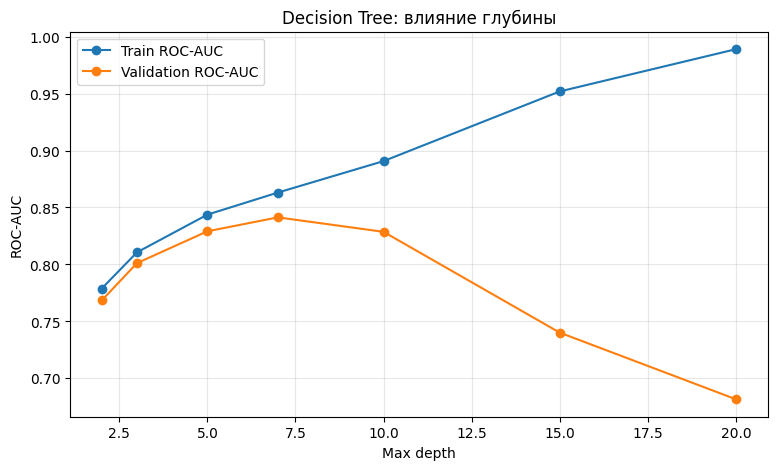

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(depth_results["depth"],
         depth_results["train_auc"],
         marker="o", label="Train ROC-AUC")

plt.plot(depth_results["depth"],
         depth_results["val_auc"],
         marker="o", label="Validation ROC-AUC")

plt.xlabel("Max depth")
plt.ylabel("ROC-AUC")
plt.title("Decision Tree: влияние глубины")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Вывод.** Лучшая валидационная оценка среди проверенных глубин — 0.8412 при глубине 7. При глубине 20 обучающий ROC-AUC увеличивается до 0.9890, а валидационный снижается до 0.6814. Эта картина поддерживает гипотезу о переобучении слишком глубокого дерева.

<a id="exp-leaf"></a>

### 5.3. Минимальный размер листа — продолжение H3

При фиксированной глубине 15 изменяется только `min_samples_leaf`. В сохранённом коде проверены значения 1, 5, 20, 50 и 10 000.

In [ ]:
for leaf_size in [1, 5, 20, 50, 10000]:
    tree = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=15,
            min_samples_leaf=leaf_size,
            random_state=42
        ))
    ])

    tree.fit(X_train, y_train)

    train_auc = roc_auc_score(
        y_train, tree.predict_proba(X_train)[:, 1]
    )

    val_auc = roc_auc_score(
        y_val, tree.predict_proba(X_val)[:, 1]
    )

    print(leaf_size, round(train_auc, 4), round(val_auc, 4))

1 0.9519 0.74
5 0.9421 0.7896
20 0.9191 0.8265
50 0.8989 0.8429
10000 0.799 0.7883


**Вывод по сохранённому расчёту.** Увеличение `min_samples_leaf` с 1 до 50 снижает Train ROC-AUC с 0.9519 до 0.8989 и повышает Validation ROC-AUC с 0.7400 до 0.8429. При значении 10 000 обе оценки снижаются: 0.7990 на обучении и 0.7883 на валидации. Слишком сильное ограничение также ухудшает качество.


<a id="exp-cv"></a>

### 5.4. Сравнение исходных моделей на временной CV

Обе модели переобучаются на каждом из трёх разбиений из раздела 3.5. Сравниваются значения ROC-AUC по фолдам, их среднее и разброс.

In [ ]:
from sklearn.model_selection import cross_validate

models = {
    "Logistic Regression": model,
    "Random Forest": forest_model
}

cv_results = {}

for name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X_cv,
        y_cv,
        cv=cv_splits,
        scoring="roc_auc",
        n_jobs=1
    )

    cv_results[name] = scores["test_score"]

results_df = pd.DataFrame(cv_results)

display(results_df.round(4))
display(results_df.agg(["mean", "std"]).round(4))

,Logistic Regression,Random Forest
0,0.8664,0.8562
1,0.8688,0.8630
2,0.8707,0.8645


,Logistic Regression,Random Forest
mean,0.8686,0.8612
std,0.0022,0.0044


**Вывод.** Логистическая регрессия имеет больший ROC-AUC на всех трёх фолдах: среднее 0.8686 против 0.8612 у исходного Random Forest. Стандартные отклонения по этим трём периодам равны 0.0022 и 0.0044 соответственно. Это описание полученных результатов, а не отдельная проверка статистической значимости.

<a id="exp-regularization"></a>

### 5.5. Подбор L2-регуляризации — H4

GridSearchCV сравнивает `C ∈ {0.01, 0.1, 1, 10}`. Остальные настройки и временные фолды одинаковы.

In [ ]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=model,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10]
    },
    scoring="roc_auc",
    cv=cv_splits,
    n_jobs=1,
    return_train_score=True
)

grid_search.fit(X_cv, y_cv)

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

Best parameters: {'classifier__C': 0.1}
Best CV ROC-AUC: 0.8690799843585982


In [ ]:
pd.DataFrame(grid_search.cv_results_)[
    [
        "param_classifier__C",
        "mean_train_score",
        "mean_test_score",
        "std_test_score"
    ]
].round(4)

,param_classifier__C,mean_train_score,mean_test_score,std_test_score
0,0.01,0.8757,0.8677,0.0022
1,0.10,0.8786,0.8691,0.0014
2,1.00,0.8787,0.8686,0.0018
3,10.00,0.8787,0.8685,0.0019


**Вывод.** Лучший средний CV ROC-AUC получен при `C=0.1`: 0.8691. Выигрыш относительно `C=1` составляет около 0.0005. В исследованном диапазоне качество слабо зависит от силы регуляризации; наблюдаемый небольшой прирост не объявляется статистически значимым.

При стандартном `refit=True` выбранная конфигурация после поиска обучается на всём `X_cv`. Её нельзя оценивать на прежней `val_df` как на независимой выборке.

<a id="exp-forest-search"></a>

### 5.6. Подбор параметров Random Forest — H5

RandomizedSearchCV проверяет 8 комбинаций из заданного набора глубин, минимальных размеров листа и `max_features`. Используются те же временные фолды.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

forest_search = RandomizedSearchCV(
    estimator=forest_model,
    param_distributions={
        "classifier__max_depth": [8, 12, 16],
        "classifier__min_samples_leaf": [5, 20, 50, 100],
        "classifier__max_features": ["sqrt", 0.7]
    },
    n_iter=8,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=42,
    n_jobs=1,
    return_train_score=True
)

forest_search.fit(X_cv, y_cv)

print("Best parameters:", forest_search.best_params_)
print("Best ROC-AUC:", forest_search.best_score_)

Best parameters: {'classifier__min_samples_leaf': 20, 'classifier__max_features': 0.7, 'classifier__max_depth': 12}
Best ROC-AUC: 0.8702212375201066


**Вывод.** Лучший найденный вариант — `max_depth=12`, `min_samples_leaf=20`, `max_features=0.7`. Средний CV ROC-AUC повышается с 0.8612 до 0.8702. Это результат ограниченного поиска, а не гарантия глобально оптимальной конфигурации.

<a id="exp-indicators"></a>

### 5.7. Индикаторы пропусков — H2

Сравниваются две логистические регрессии с `C=0.1`: базовая и с `add_indicator=True` для числового imputer. Меняется только этот элемент предобработки.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

# Модель без индикаторов
lr_base = clone(grid_search.best_estimator_)

# Модель с индикаторами
lr_with_indicators = clone(grid_search.best_estimator_)

lr_with_indicators.set_params(
    preprocessor__num__imputer__add_indicator=True
)

for name, estimator in {
    "Без индикаторов": lr_base,
    "С индикаторами": lr_with_indicators
}.items():

    scores = cross_validate(
        estimator,
        X_cv,
        y_cv,
        cv=cv_splits,
        scoring="roc_auc",
        n_jobs=1
    )["test_score"]

    print(name)
    print("По фолдам:", scores.round(4))
    print("Средний ROC-AUC:", round(scores.mean(), 4))
    print()

Без индикаторов
По фолдам: [0.8675 0.8689 0.8709]
Средний ROC-AUC: 0.8691

С индикаторами
По фолдам: [0.8682 0.8717 0.8751]
Средний ROC-AUC: 0.8717



**Вывод.** Средний CV ROC-AUC увеличивается с 0.8691 до 0.8717; прирост наблюдается на каждом фолде. Гипотеза получает поддержку в данном эксперименте. Добавлены индикаторы всех числовых признаков с пропусками в обучающей части фолда, поэтому прирост нельзя приписать только `Sunshine_missing`.

<a id="exp-selection"></a>

### 5.8. Отбор признаков — H6

SelectKBest с ANOVA F-statistic сохраняет 20 столбцов **после** предобработки и One-Hot Encoding. Отбор включён внутрь Pipeline и выполняется заново на обучающей части каждого фолда.

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.base import clone

selected_model = Pipeline([
    ("preprocessor",
     clone(lr_with_indicators.named_steps["preprocessor"])),

    ("selection",
     SelectKBest(score_func=f_classif, k=20)),

    ("classifier",
     clone(lr_with_indicators.named_steps["classifier"]))
])

In [ ]:
for name, estimator in {
    "All features": lr_with_indicators,
    "Top 20 features": selected_model
}.items():

    scores = cross_validate(
        estimator,
        X_cv,
        y_cv,
        cv=cv_splits,
        scoring="roc_auc",
        n_jobs=1
    )["test_score"]

    print(name, scores.round(4))
    print("Mean:", round(scores.mean(), 4))

All features [0.8682 0.8717 0.8751]
Mean: 0.8717
Top 20 features [0.8665 0.8615 0.8679]
Mean: 0.8653


**Вывод.** Сокращение числа признаков снижает средний CV ROC-AUC с 0.8717 до 0.8653. Ухудшение наблюдается на всех трёх фолдах; гипотеза о сохранении качества не подтвердилась. Далее полный предтестовый период используется только для просмотра списка отобранных столбцов, а не для новой независимой оценки.

In [ ]:
selected_model.fit(X_cv, y_cv)

feature_names = (
    selected_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

selector = selected_model.named_steps["selection"]

selected_features = pd.DataFrame({
    "Feature": feature_names[selector.get_support()],
    "F_score": selector.scores_[selector.get_support()]
})

display(
    selected_features.sort_values(
        "F_score", ascending=False
    )
)

,Feature,F_score
9,num__Humidity3pm,27228.001257
4,num__Sunshine,14678.381794
18,cat__RainToday_No,11833.710590
19,cat__RainToday_Yes,11833.710590
13,num__Cloud3pm,11429.458648
8,num__Humidity9am,7866.543903
12,num__Cloud9am,7865.513906
2,num__Rainfall,6580.024522
10,num__Pressure9am,6116.581813
5,num__WindGustSpeed,5664.438134


**Интерпретация.** Наибольшие индивидуальные F-score у `Humidity3pm` и `Sunshine`. Оба столбца `RainToday_No` и `RainToday_Yes` попали в отбор и имеют одинаковую оценку. Среди индикаторов выбран `missingindicator_Rainfall`. F-score — индивидуальный критерий отбора, а не величина вклада признака в итоговый ROC-AUC. Для дальнейших моделей сохранён полный набор признаков.

<a id="exp-sunshine"></a>

### 5.9. Исключение Sunshine — H1

Сравниваются модели с полной информацией о `Sunshine` и без неё. Во втором варианте исключается как сам столбец, так и индикатор его пропуска; остальные условия одинаковы.

In [ ]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate

# Модель со всеми признаками
with_sun = clone(lr_with_indicators)

# Создаем предобработку без Sunshine
base_prep = lr_with_indicators.named_steps["preprocessor"]

no_sun_prep = ColumnTransformer([
    (
        "num",
        clone(base_prep.transformers[0][1]),
        [c for c in num_cols if c != "Sunshine"]
    ),
    (
        "cat",
        clone(base_prep.transformers[1][1]),
        cat_cols
    )
])

# Модель без Sunshine
without_sun = clone(lr_with_indicators)
without_sun.set_params(preprocessor=no_sun_prep)

# Сравнение
for name, estimator in {
    "With Sunshine": with_sun,
    "Without Sunshine": without_sun
}.items():

    scores = cross_validate(
        estimator,
        X_cv,
        y_cv,
        cv=cv_splits,
        scoring="roc_auc",
        n_jobs=1
    )["test_score"]

    print(name, scores.round(4))
    print("Mean ROC-AUC:", round(scores.mean(), 4))
    print()

With Sunshine [0.8682 0.8717 0.8751]
Mean ROC-AUC: 0.8717

Without Sunshine [0.866  0.8692 0.8719]
Mean ROC-AUC: 0.869



**Вывод.** С `Sunshine` средний CV ROC-AUC равен 0.8717, без него — 0.8690. Прирост около 0.0027 наблюдается на всех трёх фолдах. Гипотеза поддерживается для всего блока информации о `Sunshine`; отдельные вклады значения и индикатора здесь не разделены.

<a id="exp-season"></a>

### 5.10. Сезонные признаки — H7

Из даты создаются два циклических признака:

$$
\mathrm{month\_sin}=\sin\left(\frac{2\pi m}{12}\right),\qquad
\mathrm{month\_cos}=\cos\left(\frac{2\pi m}{12}\right),
$$

где $m$ — номер месяца. К базовой логистической регрессии с индикаторами добавляются только эти два столбца. Взаимодействия месяца с местоположением не создаются.

In [ ]:
X_cv_season = X_cv.copy()

month = train_df["Date"].dt.month

X_cv_season["month_sin"] = np.sin(2 * np.pi * month / 12)
X_cv_season["month_cos"] = np.cos(2 * np.pi * month / 12)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

base_prep = lr_with_indicators.named_steps["preprocessor"]

season_prep = ColumnTransformer([
    (
        "num",
        clone(base_prep.transformers[0][1]),
        num_cols + ["month_sin", "month_cos"]
    ),
    (
        "cat",
        clone(base_prep.transformers[1][1]),
        cat_cols
    )
])

season_model = clone(lr_with_indicators)
season_model.set_params(preprocessor=season_prep)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MinTemp', 'MaxTemp',
                                                   'Rainfall', 'Evaporation',
                                                   'Sunshine', 'WindGustSpeed',
                                                   'WindSpeed9am',
                                                   'WindSpeed3pm',
                                                   'Humidity9am', 'Humidity3pm',
                                                   'Pressure9am', 'Pressure3pm',
                                                   'Cloud9am', 'Cloud3pm',
                                                   'Temp9am', 'Temp3pm',
                                                   'month_sin', 'month_cos']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Location', 'WindGustDir',
                                                   'WindDir9am', 'WindDir3pm',
                                                   'RainToday'])])),
                ('classifier',
                 LogisticRegression(C=0.1, max_iter=1000, random_state=42))])

In [ ]:
for name, estimator in {
    "Without season": lr_with_indicators,
    "With season": season_model
}.items():

    scores = cross_validate(
        estimator,
        X_cv_season,
        y_cv,
        cv=cv_splits,
        scoring="roc_auc",
        n_jobs=1
    )["test_score"]

    print(name, scores.round(4))
    print("Mean ROC-AUC:", round(scores.mean(), 4))

Without season [0.8682 0.8717 0.8751]
Mean ROC-AUC: 0.8717
With season [0.869  0.8711 0.8757]
Mean ROC-AUC: 0.8719


**Вывод.** Средний CV ROC-AUC изменился с 0.8717 до 0.8719. На втором фолде качество снизилось. Убедительной поддержки заметного улучшения нет; дальнейшее усложнение сезонных признаков в этой работе не проводилось.

<a id="exp-choice"></a>

### 5.11. Сводка CV и выбор финальной конфигурации

| Проверенная конфигурация | Средний CV ROC-AUC |
|:--|--:|
| Logistic Regression, C=0.1 | 0.8691 |
| Random Forest после настройки | 0.8702 |
| **Logistic Regression, C=0.1, индикаторы пропусков** | **0.8717** |
| Та же модель + сезонные признаки | 0.8719 |
| Та же модель + SelectKBest(k=20) | 0.8653 |
| Та же модель без Sunshine и его индикатора | 0.8690 |

**Выбор до теста:** логистическая регрессия с `C=0.1`, всеми признаками и индикаторами пропусков, без сезонности. Добавление сезонности дало только 0.0002 к среднему ROC-AUC, поэтому сохранена более простая конфигурация. Для финальных классов фиксируется порог **0.5**.

Таблица объединяет сохранённые оценки на одинаковых фолдах. Варианты используют разную предобработку и наборы признаков; это сравнение исследованных конфигураций, а не доказательство общего превосходства одного семейства алгоритмов.

<a id="test"></a>

## 6. Финальное тестирование

Выбранная конфигурация переобучается на всём `train_df` и оценивается на `test_df` начиная с 8 августа 2015 года. После этой оценки гиперпараметры, набор признаков и порог по тестовым результатам не подбираются.

<a id="test-metrics"></a>

### 6.1. Обучение выбранной модели и метрики

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

# Зафиксированная конфигурация модели
final_model = clone(lr_with_indicators)

# Данные для финального обучения
X_train_final = train_df[features]
y_train_final = (
    train_df["RainTomorrow"] == "Yes"
).astype(int)

# Независимая тестовая выборка
X_test = test_df[features]
y_test = (
    test_df["RainTomorrow"] == "Yes"
).astype(int)

# Обучение на всём train
final_model.fit(X_train_final, y_train_final)

# Предсказания на test
y_test_proba = final_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= 0.5).astype(int)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba)
}

display(pd.Series(final_metrics).round(4))
print(confusion_matrix(y_test, y_test_pred))

Accuracy     0.8473
Precision    0.7240
Recall       0.4906
F1           0.5849
ROC-AUC      0.8628
dtype: float64

[[24331  1349]
 [ 3673  3538]]


**Результат.** Тестовый ROC-AUC = **0.8628**, Accuracy = **0.8473**, Precision = **0.7240**, Recall = **0.4906**, F1 = **0.5849**. Средний CV ROC-AUC выбранной конфигурации составлял 0.8717; разница с тестовым периодом — около −0.0089.

Из 7211 наблюдений класса `Yes` модель обнаружила 3538 и пропустила 3673. При пороге 0.5 основным ограничением остаётся Recall: обнаружена примерно половина дождливых следующих дней.

<a id="test-risk"></a>

### 6.2. Проверка исключения RISK_MM

Сохраняется проверка исходной таблицы, списка признаков и входных столбцов финальной модели.

In [ ]:
print("RISK_MM в исходных данных:", "RISK_MM" in df.columns)
print("RISK_MM среди признаков:", "RISK_MM" in features)
print("RISK_MM в финальной модели:",
      "RISK_MM" in final_model.feature_names_in_)

RISK_MM в исходных данных: False
RISK_MM среди признаков: False
RISK_MM в финальной модели: False


**Результат проверки:** `RISK_MM` отсутствует во всех трёх проверяемых объектах. Кроме того, этот столбец явно включён в список исключений при подготовке `features`.

<a id="test-roc"></a>

### 6.3. ROC-кривая на тестовом периоде

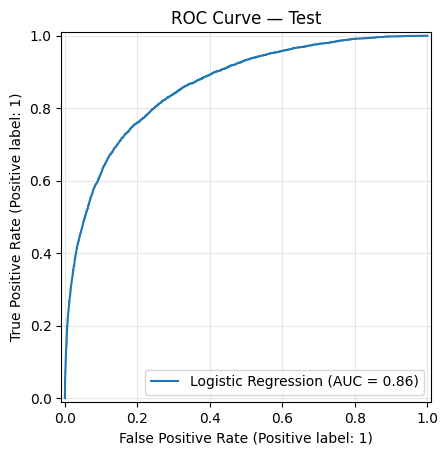

In [ ]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    RocCurveDisplay,
    ConfusionMatrixDisplay
)

RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name="Logistic Regression"
)

plt.title("ROC Curve — Test")
plt.grid(alpha=0.3)
plt.show()

<a id="test-confusion"></a>

### 6.4. Матрица ошибок при пороге 0.5

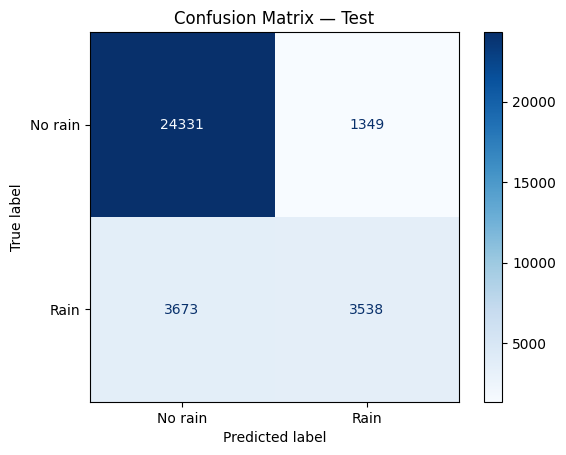

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No rain", "Rain"],
    cmap="Blues"
)

plt.title("Confusion Matrix — Test")
plt.show()

| Фактический класс / прогноз | No | Yes |
|:--|--:|--:|
| **No** | 24 331 (TN) | 1349 (FP) |
| **Yes** | 3673 (FN) | 3538 (TP) |

Сумма элементов матрицы — 32 891, что соответствует размеру тестовой выборки. Все классификационные метрики в этом разделе относятся к положительному классу `Yes`, кроме общей Accuracy.

<a id="conclusions"></a>

## 7. Выводы

Выводы основаны на сохранённых результатах экспериментов. Оценки на одной начальной валидации, средние оценки временной CV и финальная тестовая оценка ниже не смешиваются.

<a id="conclusions-hypotheses"></a>

### 7.1. Итог по семи гипотезам

| Гипотеза | Основной результат | Вывод |
|:--|:--|:--|
| **H1. Польза Sunshine** | CV ROC-AUC: 0.8690 без блока → 0.8717 с блоком. | Предварительно подтверждается на всех трёх фолдах; удалялся также индикатор пропуска. |
| **H2. Индикаторы пропусков** | CV ROC-AUC: 0.8691 → 0.8717. | Предварительно подтверждается; вклад отдельных индикаторов не выделен. |
| **H3. Переобучение дерева** | При глубине 7 → 20 Train AUC: 0.8630 → 0.9890; Validation AUC: 0.8412 → 0.6814. | Поддерживается экспериментом. Ограничение размера листа помогает, чрезмерное ограничение ухудшает результат. |
| **H4. L2-регуляризация** | Лучшее C=0.1; CV ROC-AUC 0.8691 против 0.8686 при C=1. | Частичное подтверждение; прирост 0.0005 очень мал. |
| **H5. Настройка Random Forest** | CV ROC-AUC: 0.8612 → 0.8702. | Поддерживается в рамках проведённого поиска. |
| **H6. Top 20 без потери качества** | CV ROC-AUC: 0.8717 → 0.8653. | Не подтвердилась; ухудшение на всех трёх фолдах. |
| **H7. Сезонность** | CV ROC-AUC: 0.8717 → 0.8719. | Убедительной поддержки заметного улучшения нет. |

<a id="conclusions-interpretation"></a>

### 7.2. Интерпретация результатов

`Sunshine` показывает выраженную индивидуальную связь с целевой переменной, но даёт сравнительно небольшой дополнительный прирост ROC-AUC. Возможное объяснение — частичное дублирование информации другими погодными показателями; это не было отдельно доказано.

Индикаторы пропусков улучшили оценки логистической регрессии на всех трёх фолдах. Они позволяют отличать измеренные значения от подставленных. Эксперимент оценивает набор индикаторов целиком, а не причинный механизм возникновения пропусков.

Эксперименты с деревом показали обе крайности: слишком глубокое дерево хорошо описывает обучение и теряет качество на валидации, а слишком большой минимальный размер листа ограничивает полезную гибкость. По сохранённому циклу при глубине 15 переход от `min_samples_leaf=1` к `50` повысил Validation ROC-AUC с 0.7400 до 0.8429; при 10 000 оценка снизилась до 0.7883.

Подбор гиперпараметров заметнее изменил результат Random Forest, чем логистической регрессии. При этом более сложная модель не обеспечила наибольший ROC-AUC среди всех исследованных конфигураций. Отбор 20 столбцов ухудшил качество, а добавление двух сезонных признаков практически его не изменило.

<a id="conclusions-final"></a>

### 7.3. Финальная модель и результат

Выбрана **логистическая регрессия с L2-регуляризацией (`C=0.1`)**, заполнением числовых пропусков медианой, масштабированием, заполнением категориальных пропусков наиболее частым значением, One-Hot Encoding и индикаторами числовых пропусков. Сохраняются все исходно выбранные признаки; сезонные столбцы и SelectKBest в итоговую модель не включены.

| Метрика на отложенном тестовом периоде | Значение |
|:--|--:|
| Accuracy | 0.8473 |
| Precision | 0.7240 |
| Recall | 0.4906 |
| F1 | 0.5849 |
| ROC-AUC | 0.8628 |

**Общий вывод:** в рамках этого исследования логистическая регрессия с корректной предобработкой обеспечивает удачное соотношение качества и сложности.положительного класса.